# 04 · Two consecutive X pulses

A second X pulse should undo the first: $X\cdot X = I$. This notebook
concatenates the pulses of notebooks 01 and 03 and checks the fidelity, the
leakage, and the noise response of the sequence.

**Order of operations.** DRAG is applied to each pulse on its own, and the
corrected pulses are then placed back to back. The derivative in the DRAG
formula is taken over one gate, and $T_g\alpha$ stays the anharmonicity of
one gate. Concatenating first and differentiating over the whole sequence
would divide that derivative by two.

**Time.** `concatenate_control_dicts` keeps each pulse's fields and joins
the time grids, so the sequence runs from $0$ to $2$ in units of one
$T_g$. The simulators scale every term by `times[-1]`, which is $2$ here.
Passing the same `tg_alpha` as for one pulse is therefore correct: the
$|2\rangle$ phase accumulated over the sequence is $2T_g\alpha$. A static
dephasing $\delta_z$ is accumulated for twice as long. Where an axis is
labeled $T_g\delta_z$, it is the noise strength times one gate time, so it
can be compared with the earlier notebooks.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qurveros import controltools, drag
from qurveros import plottools
from qurveros.qubit_bench import noise_experiments, quantumtools, simulator
import qurveros.plot_configs

import xgate_setup as xs

matplotlib.rcParams['figure.dpi'] = 150

identity = xs.IDENTITY
bare = xs.xgate_control()
tg_alpha = xs.tg_alpha()
orders = (0, 1, 2)
colors = {0: 'k', 1: 'tab:blue', 2: 'tab:orange'}

single = {order: drag.apply_drag(bare, tg_alpha, order=order, beta=1.0, lam=xs.LAM)
          for order in orders}
sequence = {order: controltools.concatenate_control_dicts(pulse, pulse)
            for order, pulse in single.items()}
print('sequence duration in units of one T_g:', sequence[0]['times'][-1])
print('junction samples:', sequence[0]['pulse_boundaries'])

sequence duration in units of one T_g: 2.0
junction samples: [1. 2.]


## Does the sequence equal the product of the gates?

The simulated sequence is compared with the product of the two single-pulse
propagators, and with the identity.

In [2]:
rows = {}
qubit_gates = {}
for order in orders:
    one = simulator.simulate_control_dict(single[order], xs.U_TARGET)
    both = simulator.simulate_control_dict(sequence[order], identity)
    product = one['u_final'] @ one['u_final']
    qubit_gates[order] = both
    rows[f'order {order}'] = {
        'fidelity of X·X to I': both['avg_gate_fidelity'],
        'fidelity of X·X to X·X': quantumtools.calculate_gate_fidelity(both['u_final'], product),
        'fidelity of one X to X': one['avg_gate_fidelity'],
    }
pd.DataFrame(rows)

,order 0,order 1,order 2
fidelity of X·X to I,1.0,0.999783,0.999982
fidelity of X·X to X·X,1.0,1.000000,1.000000
fidelity of one X to X,1.0,0.997551,0.997493


**Reading the table.**

- The concatenated evolution reproduces the product of the two gates to
  the accuracy of the ODE solver, for every order. The join does not add a
  phase jump or a rescaling.
- **Order 0.** Each pulse is an X, and the sequence is the identity.
- **Orders 1 and 2.** One corrected pulse misses X by about $2.5\times10^{-3}$
  in infidelity. The sequence misses the identity by $2.2\times10^{-4}$
  (order 1) and $1.8\times10^{-5}$ (order 2). The second pulse undoes most
  of the rotation error that DRAG left on the first, because conjugating
  that small error by X reverses it.

## Two-level robustness of the sequence

$|\vec r_z|$ and $|\vec r_\varepsilon|$ are calculated for one pulse and for
the sequence. The sweeps use $T_g\delta_z$ of a single gate as the axis.
The sequence feels that noise for twice as long, so the predicted
infidelity is $(2\,T_g\delta_z)^2|\vec r_z|^2/6$.

In [3]:
tg_delta_z = np.logspace(-3, 0, 11)
epsilons = np.logspace(-4, -1, 11)

vectors = {}
sweeps = {}
for order in orders:
    vectors[order] = {
        'one': simulator.first_order_error_vectors(single[order]),
        'sequence': simulator.first_order_error_vectors(sequence[order]),
    }
    sweeps[order] = xs.sensitivity_sweep(
        sequence[order], 'dephasing', tg_delta_z, u_target=identity)

pd.DataFrame({
    f'order {order}': {
        '|r_z|, one pulse': vectors[order]['one']['r_z_norm'],
        '|r_z|, sequence': vectors[order]['sequence']['r_z_norm'],
        '|r_eps|, one pulse': vectors[order]['one']['r_epsilon_norm'],
        '|r_eps|, sequence': vectors[order]['sequence']['r_epsilon_norm'],
    }
    for order in orders
})

,order 0,order 1,order 2
"|r_z|, one pulse",6.709620e-12,0.105375,0.104686
"|r_z|, sequence",8.978988e-14,0.102874,0.102762
"|r_eps|, one pulse",1.089444e-02,0.262600,0.370036
"|r_eps|, sequence",1.987235e-02,0.508862,0.724783


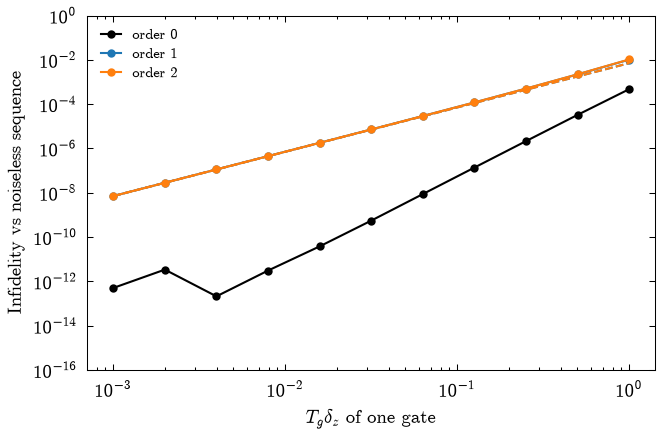

order 0    3.928167
order 1    2.067149
order 2    2.071236
Name: dephasing slope of X·X, dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(4.4, 2.9), layout='constrained')
for order in orders:
    r_norm = vectors[order]['sequence']['r_z_norm']
    ax.loglog(tg_delta_z, sweeps[order]['sensitivity'], 'o-', ms=3,
              color=colors[order], label=f'order {order}')
    ax.loglog(tg_delta_z, (2 * tg_delta_z * r_norm)**2 / 6, '--', color=colors[order])
ax.set_xlabel(r'$T_g\delta_z$ of one gate')
ax.set_ylabel('Infidelity vs noiseless sequence')
ax.set_ylim(1e-16, 1)
ax.legend(fontsize=7)
plt.show()

pd.Series({
    f'order {order}': xs.loglog_slope(tg_delta_z[3:], sweeps[order]['sensitivity'][3:])
    for order in orders
}, name='dephasing slope of X·X')

**Reading the sweeps.**

- **Order 0** stays closed. $|\vec r_z|$ of the sequence is $\sim 10^{-13}$,
  and the response has no first-order term.
- **Orders 1 and 2** have $|\vec r_z|\approx 0.103$ for the sequence against
  $0.105$ for one pulse. Playing X twice does not echo this error away: the
  DRAG detuning of the second pulse adds in the toggling frame instead of
  cancelling the first. Because the sequence also lasts twice as long, the
  infidelity at a given $\delta_z$ is about four times the infidelity of one
  corrected pulse. The dashed line is that prediction, and it lies on the
  simulated points.
- $|\vec r_\varepsilon|$ roughly doubles from one pulse to the sequence, so
  the drive errors add.

The two-level noise contours, with the vertical axis relabeled per gate so
it matches notebooks 01 and 03.

Static additive dephasing and multiplicative driving field experiment



Multiplicative driving field error:	 0.00 %
	 \---- Static additive dephasing error:	25.00 %

	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	75.00 %

	 \---- Static additive dephasing error:	91.67 %

...

	 \---- Static additive dephasing error:	25.00 %

	 \---- Static additive dephasing error:	41.67 %

	 \---- Static additive dephasing error:	66.67 %

	 \---- Static additive dephasing error:	91.67 %

Multiplicative driving field error:	100.00%
/opt/qurveros-venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 183 (\N{MIDDLE DOT}) missing from font(s) cmr10.
  fig.canvas.print_figure(bytes_io, **kw)


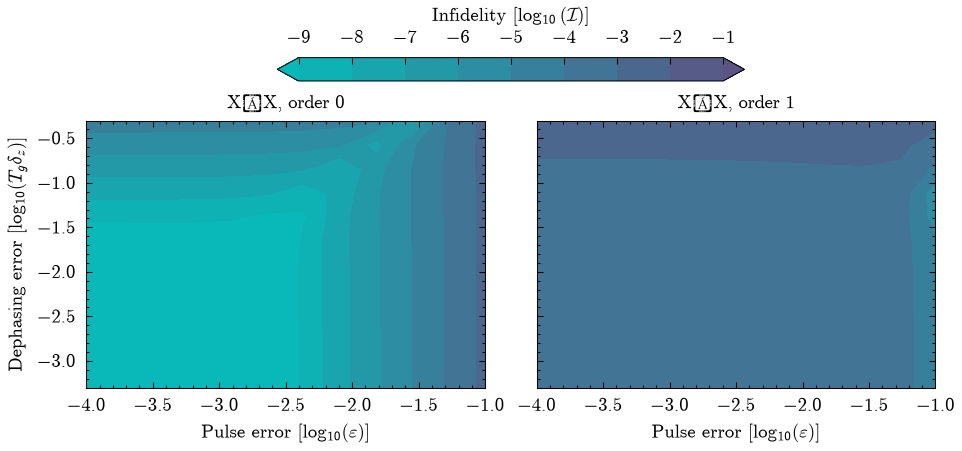

In [5]:
contours = {}
for order in (0, 1):
    result = noise_experiments.simult_source_experiment(sequence[order], identity)
    contours[order] = xs.per_pulse_axis(result, n_pulses=2)
    xs.save_result(f'contour_xx_qubit_order{order}', contours[order])

levels = np.arange(-9, 0)
fig, axs = plt.subplots(1, 2, figsize=(6.4, 3), layout='constrained', sharey=True)
for ax, order in zip(axs, (0, 1)):
    contour = plottools.plot_noise_contour(contours[order], levels=levels, ax=ax)
    ax.set_title(f'X·X, order {order}', fontsize=9)
axs[1].set_ylabel('')
fig.colorbar(contour, ax=axs, location='top', shrink=0.55,
             label=r'Infidelity $[\log_{10}(\mathcal{I})]$')
plt.show()

## Leakage of the sequence

Final leakage, peak leakage, and the first-order calculation, compared with
one pulse and with twice one pulse. Twice one pulse is what leakage would
do if the two gates simply added and did not interfere.

In [6]:
rows = {}
qutrit = {}
for order in orders:
    one = simulator.simulate_qutrit(single[order], xs.U_TARGET, tg_alpha, lam=xs.LAM)
    both = simulator.simulate_qutrit(sequence[order], identity, tg_alpha, lam=xs.LAM)
    calculated = drag.first_order_leakage(sequence[order], tg_alpha, lam=xs.LAM)
    budget = xs.error_budget(both['u_final'], identity)
    qutrit[order] = (one, both, calculated)
    rows[f'order {order}'] = {
        'leakage, one X': one['leakage'],
        'leakage, X·X': both['leakage'],
        'twice one X': 2 * one['leakage'],
        'X·X, first order': calculated['leakage'],
        'peak, one X': one['peak_leakage'],
        'peak, X·X': both['peak_leakage'],
        'peak, first order': calculated['leakage_trace'].max(),
        'coherent infidelity of X·X': budget['coherent_infidelity'],
        'subspace infidelity of X·X': budget['subspace_infidelity'],
    }
pd.DataFrame(rows)

,order 0,order 1,order 2
"leakage, one X",0.020133,0.001057,0.000951
"leakage, X·X",0.035291,0.000568,0.000640
twice one X,0.040265,0.002114,0.001903
"X·X, first order",0.006941,0.001193,0.001153
"peak, one X",0.051293,0.015435,0.014812
"peak, X·X",0.063366,0.017576,0.016732
"peak, first order",0.074700,0.017302,0.016992
coherent infidelity of X·X,0.026278,0.000039,0.000004
subspace infidelity of X·X,0.060840,0.000607,0.000644


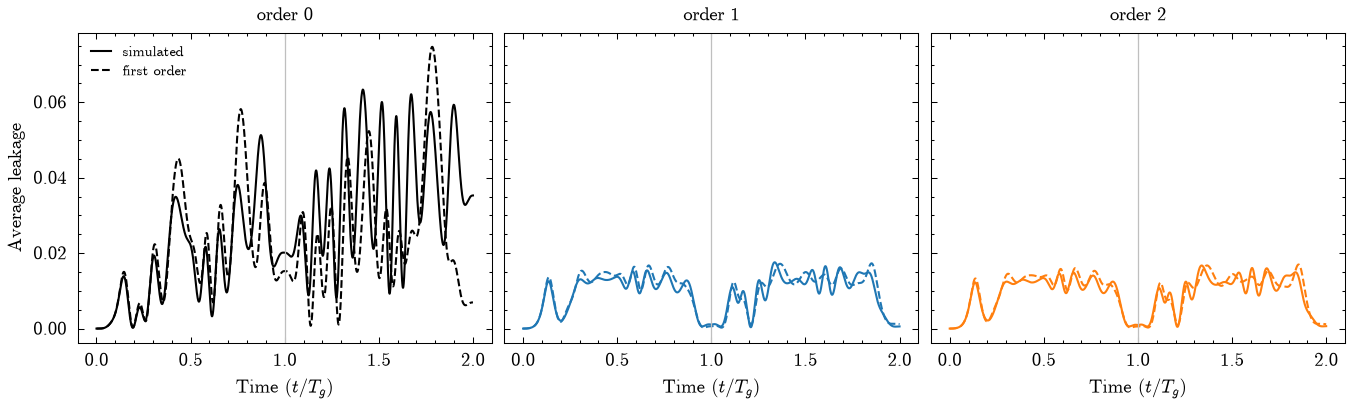

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), layout='constrained', sharey=True)
for ax, order in zip(axs, orders):
    one, both, calculated = qutrit[order]
    boundary = sequence[order]['pulse_boundaries'][0]
    ax.plot(both['times'], both['leakage_trace'], color=colors[order], label='simulated')
    ax.plot(calculated['times'], calculated['leakage_trace'], '--', color=colors[order],
            label='first order')
    ax.axvline(boundary, color='0.75', lw=0.6)
    ax.set_title(f'order {order}', fontsize=9)
    ax.set_xlabel(r'Time $(t/T_g)$')
axs[0].set_ylabel('Average leakage')
axs[0].legend(fontsize=7)
plt.show()

**Reading the leakage.**

- The vertical line is the join. Each half has the shape of one pulse.
- **Order 0.** The final leakage is $3.5\times10^{-2}$, against
  $2.0\times10^{-2}$ for one pulse and $4.0\times10^{-2}$ for twice that.
  The two leakage amplitudes interfere rather than adding in probability.
  The peak during the sequence, $6.3\times10^{-2}$, is higher than the peak
  of one pulse.
- **Orders 1 and 2.** The second pulse brings population back. The final
  leakage of the sequence is about $6\times10^{-4}$, *below* the
  $1\times10^{-3}$ of a single corrected pulse, while the peak still sits
  near $1.7\times10^{-2}$.
- The first-order calculation follows the transient through both pulses.
  The final value, where the two pulses interfere, is the part it misses.
  For the bare sequence it ends low: $6.9\times10^{-3}$ calculated against
  $3.5\times10^{-2}$ simulated. After DRAG it ends high: $1.2\times10^{-3}$
  calculated against $5.7\times10^{-4}$ simulated for order 1.

## Dephasing robustness on the qutrit

Same construction as notebook 03: the infidelity of the noisy sequence
against the noiseless sequence, on the qubit subspace. The dashed lines are
the two-level result of the sequence, copied from the sweep above.

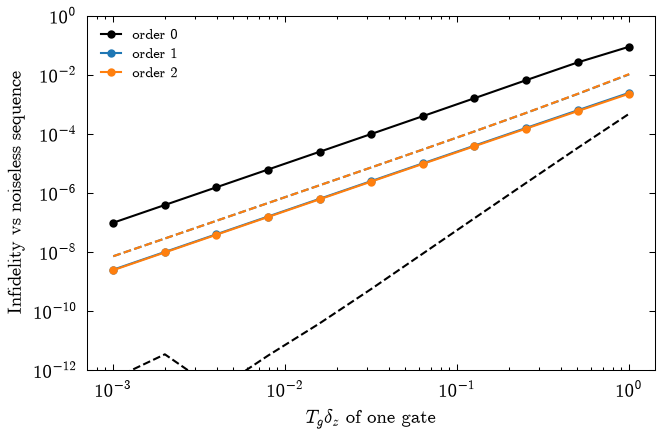

,order 0,order 1,order 2
qubit slope,3.928167,2.067149e+00,2.071236e+00
qutrit slope,2.000366,1.997784e+00,1.993486e+00
qutrit S at 0.01,0.000006,1.560958e-07,1.502730e-07


In [8]:
qutrit_sweeps = {
    order: xs.sensitivity_sweep(sequence[order], 'dephasing', tg_delta_z,
                                u_target=identity, tg_alpha_value=tg_alpha)
    for order in orders
}

fig, ax = plt.subplots(figsize=(4.4, 2.9), layout='constrained')
for order in orders:
    ax.loglog(tg_delta_z, sweeps[order]['sensitivity'], '--', color=colors[order])
    ax.loglog(tg_delta_z, qutrit_sweeps[order]['sensitivity'], 'o-', ms=3,
              color=colors[order], label=f'order {order}')
ax.set_xlabel(r'$T_g\delta_z$ of one gate')
ax.set_ylabel('Infidelity vs noiseless sequence')
ax.set_ylim(1e-12, 1)
ax.legend(fontsize=7)
plt.show()

pd.DataFrame({
    f'order {order}': {
        'qubit slope': xs.loglog_slope(tg_delta_z[3:], sweeps[order]['sensitivity'][3:]),
        'qutrit slope': xs.loglog_slope(tg_delta_z, qutrit_sweeps[order]['sensitivity']),
        'qutrit S at 0.01': float(qutrit_sweeps[order]['sensitivity'][np.argmin(np.abs(tg_delta_z - 0.01))]),
    }
    for order in orders
})

## Summary

One X against X·X, at $T_g = 50$ ns.

- **Identity, on the qubit.** The bare sequence implements $I$ essentially
  exactly. With DRAG, the sequence is closer to $I$ than either pulse is to
  $X$: the second pulse reverses the small rotation error of the first.
  On the qutrit the bare sequence is not the identity. Its subspace
  infidelity is $6.1\times10^{-2}$, from leakage plus the Stark shift of
  two pulses. DRAG brings that down to $6\times10^{-4}$.
- **Leakage adds with interference.** Bare leakage grows from
  $2.0\times10^{-2}$ to $3.5\times10^{-2}$, short of a factor of two. After
  DRAG the second pulse lowers the final leakage below that of one pulse.
- **Dephasing robustness.** The bare sequence is as closed as one pulse.
  DRAG opens it, the second pulse does not close it again, and the doubled
  duration makes the sequence about four times more sensitive than one
  corrected pulse at the same $\delta_z$. On the qutrit, DRAG still lowers
  the sensitivity relative to the bare sequence, for the same reason as in
  notebook 03: it cancels the Stark shift.
- **Calculated against simulated.** The error-vector formula tracks the
  two-level noise sweeps. The first-order leakage formula tracks the
  population during both pulses and is least accurate where the two pulses
  interfere at the very end.